# step2_popularity

**Owner:** P1  
**Purpose:** Popularity and random baseline.

**Inputs:** `data/processed/` from step 1  
**Outputs:** `outputs/results_step2_popularity.csv`, `data/scores/step2_popularity.parquet` (Test) and `data/scores/step2_popularity_tune.parquet` (Tune)

> Runtime: Colab. Run all cells top to bottom; keep outputs saved.

In [8]:
# --- Setup: run this first, every session ---
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/BT4222-Project-Group-4--MIND && git clone -q https://github.com/Fdiannz/BT4222-Project-Group-4--MIND.git /content/BT4222-Project-Group-4--MIND
import sys; sys.path.insert(0, '/content/BT4222-Project-Group-4--MIND')

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from utils.metrics import evaluate, evaluate_by_segment
print("Data folder:", config.DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/BT4222_Project/data


## Setup and Load Data
The processed files from step 1 are loaded:
- `tune_candidates` (14 Nov) and `eval_candidates` (15 Nov): one row per displayed article with its click label and cold/warm label. Both keep **full slates**, which ranking metrics need.
- `fit_impressions` (9–13 Nov) and `tune_impressions` (14 Nov): the original impression logs, used to count each article's past displays and clicks. The negative-sampled fit file is not used, because sampling raised its click rate to about 21%.

Only the columns needed are read, to save memory.

In [9]:
PROCESSED_DIR = Path(config.DATA_DIR) / "processed"
OUTPUT_DIR = Path(config.OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Candidate files: one row per displayed article (full slates)
cand_cols = ["impression_id", "news_id", "label", "time", "prior_exposure_count", "cold_article", "category"]
tune = pd.read_parquet(PROCESSED_DIR / "tune_candidates.parquet", columns=cand_cols)
evals = pd.read_parquet(PROCESSED_DIR / "eval_candidates.parquet", columns=cand_cols)

# Impression files: original logs for counting past displays and clicks
imp_cols = ["time", "impressions"]
fit_imp = pd.read_parquet(PROCESSED_DIR / "fit_impressions.parquet", columns=imp_cols)
tune_imp = pd.read_parquet(PROCESSED_DIR / "tune_impressions.parquet", columns=imp_cols)

# Check what was loaded
loaded = pd.DataFrame([
    {"file": "tune_candidates", "period": "14 Nov", "impressions": tune.impression_id.nunique(),
     "rows": len(tune), "CTR %": 100 * tune.label.mean(), "cold rows %": 100 * tune.cold_article.mean()},
    {"file": "eval_candidates", "period": "15 Nov", "impressions": evals.impression_id.nunique(),
     "rows": len(evals), "CTR %": 100 * evals.label.mean(), "cold rows %": 100 * evals.cold_article.mean()},
    {"file": "fit_impressions", "period": "9–13 Nov", "impressions": len(fit_imp), "rows": len(fit_imp)},
    {"file": "tune_impressions", "period": "14 Nov", "impressions": len(tune_imp), "rows": len(tune_imp)},
]).set_index("file")

display(loaded.style.format({"impressions": "{:,.0f}", "rows": "{:,.0f}",
                             "CTR %": "{:.2f}", "cold rows %": "{:.2f}"}, na_rep="–"))

,period,impressions,rows,CTR %,cold rows %
file,,,,,
tune_candidates,14 Nov,"431,517","17,400,106",3.86,20.99
eval_candidates,15 Nov,"376,471","14,085,557",4.08,17.93
fit_impressions,9–13 Nov,"1,801,231","1,801,231",–,–
tune_impressions,14 Nov,"431,517","431,517",–,–


## 1. Random Baseline (sanity check)

Each candidate article is assigned a random score between 0 and 1. The score does not use user, article, category, or historical click information. This provides a benchmark reference for the later baselines. Since AUC measures whether clicked articles receive higher scores than unclicked articles, random ranking should produce an AUC of approximately 0.5.

In [10]:
#randomise
rng = np.random.default_rng(config.SEED)
evals["score_random"] = rng.random(len(evals)).astype("float32")

# Evaluate: "all" row = overall, then cold / warm / mixed
random_segments = evaluate_by_segment(evals, "score_random", "cold_article")

print("Random baseline (by segments)")
display(random_segments)

Random baseline (by segments)


,auc,mrr,ndcg@5,ndcg@10,n_impressions,n_skipped
all,0.5008,0.2189,0.2238,0.2866,376471,0
cold,0.5006,0.2986,0.3181,0.3819,77199,0
warm,0.5010,0.2102,0.2104,0.2734,262807,0
mixed,0.5002,0.1128,0.1206,0.1796,36465,0


## 2. Popularity

### 2A. Historical Article Statistics

For every article and every day, we count how many times it was **displayed** and **clicked**. The counts come from the original impression files (full slates), not from the negative-sampled fit file.

Each scored day only uses **earlier days**, the same rule as the cold/warm labels in step 1:
- **14 Nov (tuning):** displays and clicks from 9–13 Nov
- **15 Nov (evaluation):** displays and clicks from 9–14 Nov

The **global CTR** (all clicks ÷ all displays) is calculated from the same days. As a check, the displays counted here must equal `prior_exposure_count` from step 1 on every row.

In [11]:
from collections import Counter

def count_article_stats(impression_dfs):
    """Count article displays and clicks from full impression slates."""

    exposures = Counter()
    clicks = Counter()

    for df in impression_dfs:
        for impression in df["impressions"]:
            for item in impression.split():
                news_id, label = item.rsplit("-", 1)

                exposures[news_id] += 1

                if label == "1":
                    clicks[news_id] += 1

    total_exposures = sum(exposures.values())
    total_clicks = sum(clicks.values())
    global_ctr = total_clicks / total_exposures

    return exposures, clicks, global_ctr

# History available before 14 Nov: 9–13 Nov
tune_exposures, tune_clicks, tune_global_ctr = count_article_stats(
    [fit_imp]
)

# History available before 15 Nov: 9–14 Nov
eval_exposures, eval_clicks, eval_global_ctr = count_article_stats(
    [fit_imp, tune_imp]
)

print("History for 14 Nov")
print(f"Articles seen: {len(tune_exposures):,}")
print(f"Exposures: {sum(tune_exposures.values()):,}")
print(f"Clicks: {sum(tune_clicks.values()):,}")
print(f"Global CTR: {tune_global_ctr:.4%}")

print("\nHistory for 15 Nov")
print(f"Articles seen: {len(eval_exposures):,}")
print(f"Exposures: {sum(eval_exposures.values()):,}")
print(f"Clicks: {sum(eval_clicks.values()):,}")
print(f"Global CTR: {eval_global_ctr:.4%}")

History for 14 Nov
Articles seen: 23,291
Exposures: 66,107,268
Clicks: 2,712,612
Global CTR: 4.1033%

History for 15 Nov
Articles seen: 27,046
Exposures: 83,507,374
Clicks: 3,383,656
Global CTR: 4.0519%


In [12]:
# Store global CTRs
global_ctr = {"tune": tune_global_ctr, "eval": eval_global_ctr}

# Add each article's historical exposures and clicks to the candidate rows
tune["hist_exposures"] = tune["news_id"].map(tune_exposures).fillna(0)
tune["hist_clicks"] = tune["news_id"].map(tune_clicks).fillna(0)
evals["hist_exposures"] = evals["news_id"].map(eval_exposures).fillna(0)
evals["hist_clicks"] = evals["news_id"].map(eval_clicks).fillna(0)

# Check: exposures must equal step 1's prior_exposure_count on every row
assert (tune["hist_exposures"] == tune["prior_exposure_count"]).all()
assert (evals["hist_exposures"] == evals["prior_exposure_count"]).all()
print("\n✓ Historical exposures match step 1 prior_exposure_count on every row")

# Free memory: the raw impression logs are no longer needed
del fit_imp, tune_imp
import gc; _ = gc.collect()


✓ Historical exposures match step 1 prior_exposure_count on every row


### 2B. Smoothed Popularity CTR

Each article's score is its past click-through rate, **smoothed** towards the global CTR:

score = (clicks + α × global CTR) / (exposures + α)

Without smoothing, an article with 1 click from 2 displays would get a CTR of 50% and rank above articles with thousands of clicks. α works like α extra displays at the global CTR added to every article: the fewer real displays an article has, the closer its score stays to the global CTR. A larger α means stronger smoothing. Articles never shown before get exactly the global CTR, so they all tie.

In [13]:
# Smoothed CTR: (clicks + alpha * global CTR) / (exposures + alpha)
def smoothed_ctr(df, alpha, ctr):
    return ((df["hist_clicks"] + alpha * ctr) / (df["hist_exposures"] + alpha)).astype("float32")

# Example: how smoothing changes the score for articles with few vs many displays
example = pd.DataFrame({"hist_exposures": [0, 2, 2, 50_000], "hist_clicks": [0, 1, 0, 2_500]},
                       index=["never shown", "1 click / 2 shown", "0 clicks / 2 shown", "2,500 clicks / 50,000 shown"])
example["raw CTR"] = (example.hist_clicks / example.hist_exposures).fillna(0)
for a in [10, 100, 1000]:
    example[f"α={a}"] = smoothed_ctr(example, a, global_ctr["tune"])
display(example.style.format({c: "{:.4f}" for c in example.columns if c not in ["hist_exposures", "hist_clicks"]}))

,hist_exposures,hist_clicks,raw CTR,α=10,α=100,α=1000
never shown,0,0,0.0000,0.0410,0.0410,0.0410
1 click / 2 shown,2,1,0.5000,0.1175,0.0500,0.0419
0 clicks / 2 shown,2,0,0.0000,0.0342,0.0402,0.0410
"2,500 clicks / 50,000 shown",50000,2500,0.0500,0.0500,0.0500,0.0498


An article with 1 click from 2 displays has a raw CTR of 50%, but with α = 100 its score drops to 0.050, close to the global CTR (0.041), because 2 displays are too few to trust. An article with 2,500 clicks from 50,000 displays keeps its real CTR (0.050) at every α, because its own data outweighs the smoothing. Articles never shown before all get the global CTR (0.041), so popularity cannot tell new articles apart.

### 2C. Tune α on the Tuning Day (14 Nov)

Five values of α are tried on 14 Nov, and the one with the highest **AUC** is kept for the final evaluation. The evaluation day (15 Nov) is not used for this choice, so the final result is not tuned to the test data.

In [14]:
# Try each alpha on the tuning day (14 Nov)
alpha_values = [10, 50, 100, 500, 1000]
pop_tuning = []
for alpha in alpha_values:
    tune["score_pop"] = smoothed_ctr(tune, alpha, global_ctr["tune"])
    pop_tuning.append({"alpha": alpha, **evaluate(tune, "score_pop")})
pop_tuning = pd.DataFrame(pop_tuning).set_index("alpha")

display(pop_tuning.style.format({"auc": "{:.4f}", "mrr": "{:.4f}", "ndcg@5": "{:.4f}",
                                 "ndcg@10": "{:.4f}", "n_impressions": "{:,.0f}"})
                  .highlight_max(subset=["auc"], color="#d4edda"))

# Keep the alpha with the highest AUC
BEST_POP_ALPHA = int(pop_tuning["auc"].idxmax())
print(f"Chosen α for popularity (highest AUC on 14 Nov): {BEST_POP_ALPHA}")

,auc,mrr,ndcg@5,ndcg@10,n_impressions,n_skipped
alpha,,,,,,
10,0.6076,0.2573,0.2693,0.3311,"431,517",0
50,0.6063,0.2528,0.2633,0.3265,"431,517",0
100,0.6040,0.2514,0.2613,0.3241,"431,517",0
500,0.6003,0.2495,0.2581,0.3206,"431,517",0
1000,0.5993,0.2483,0.2564,0.3191,"431,517",0


Chosen α for popularity (highest AUC on 14 Nov): 10


α = 10 gives the best AUC on 14 Nov (0.6076), and MRR, nDCG@5 and nDCG@10 agree. Performance falls slowly as α grows (AUC 0.5993 at α = 1,000): strong smoothing pulls every article towards the same average and hides real differences in popularity. Light smoothing works best because most articles shown have hundreds of past displays, enough to trust their own click rate.

### 2D. Do Readers Click New Articles?

Evaluation-day articles are grouped by how many times they were shown on earlier days, and the click-through rate of each group is compared with the overall CTR. Blue bars are cold articles (fewer than 10 earlier displays) and yellow bars are warm. If new articles are clicked at least as often as established ones, a popularity ranking that pushes them down will lose clicks.

,displays,% of displays,clicks,CTR %
exposure_group,,,,
0 (brand new),"757,273",5.4,"50,306",6.64
1–9,"1,768,121",12.6,"84,557",4.78
10–99,"5,029,367",35.7,"192,596",3.83
100–999,"1,036,932",7.4,"34,495",3.33
1k–9.9k,"2,612,429",18.5,"127,567",4.88
10k–99k,"2,661,310",18.9,"78,934",2.97
100k+,"220,125",1.6,"6,390",2.90


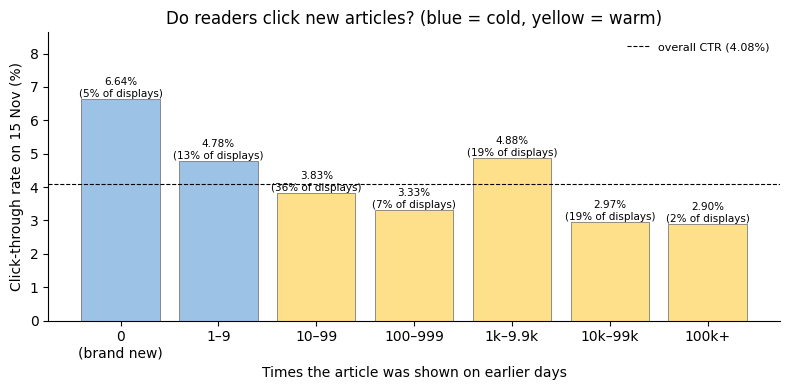

In [15]:
# D. Click rate by how often an article was shown before
bins = [0, 1, 10, 100, 1_000, 10_000, 100_000, np.inf]
labels = ["0\n(brand new)", "1–9", "10–99", "100–999", "1k–9.9k", "10k–99k", "100k+"]
evals["exposure_group"] = pd.cut(evals["prior_exposure_count"], bins=bins, right=False, labels=labels)
by_group = evals.groupby("exposure_group", observed=False).agg(
    displays=("label", "size"), clicks=("label", "sum"), ctr=("label", "mean"))
by_group["CTR %"] = 100 * by_group["ctr"]
by_group["% of displays"] = 100 * by_group["displays"] / by_group["displays"].sum()
display(by_group[["displays", "% of displays", "clicks", "CTR %"]]
        .style.format({"displays": "{:,.0f}", "% of displays": "{:.1f}", "clicks": "{:,.0f}", "CTR %": "{:.2f}"}))

overall_ctr = 100 * evals["label"].mean()
fig, ax = plt.subplots(figsize=(8, 4), facecolor="white")
colors = ["#9CC3E6", "#9CC3E6"] + ["#FFE08A"] * (len(by_group) - 2)      # cold groups blue, warm yellow
bars = ax.bar(by_group.index.astype(str), by_group["CTR %"], color=colors, edgecolor="#666666", linewidth=0.5)
for b, v, share in zip(bars, by_group["CTR %"], by_group["% of displays"]):
    if not np.isnan(v):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}%\n({share:.0f}% of displays)",
                ha="center", va="bottom", fontsize=7.5)
ax.axhline(overall_ctr, color="black", ls="--", lw=0.8, label=f"overall CTR ({overall_ctr:.2f}%)")
ax.legend(loc="upper right", frameon=False, fontsize=8)
ax.set_xlabel("Times the article was shown on earlier days"); ax.set_ylabel("Click-through rate on 15 Nov (%)")
ax.set_title("Do readers click new articles? (blue = cold, yellow = warm)")
ax.set_ylim(0, by_group["CTR %"].max() * 1.3)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 3. 📊 Final Results on the Evaluation Day (15 Nov)

The two baselines are scored **once** on 15 Nov, with popularity using the α chosen on 14 Nov (α = 10). Results are reported for all impressions and separately for impressions whose clicked articles are **cold**, **warm** or **mixed**. The table is saved to `outputs/results_step2_popularity.csv` so later models and the report can compare against it.

In [16]:
# Scores on 15 Nov with the chosen settings
evals["score_pop"] = smoothed_ctr(evals, BEST_POP_ALPHA, global_ctr["eval"])

models = {
    "Random": "score_random",
    f"Popularity (α={BEST_POP_ALPHA})": "score_pop",
}
final = pd.concat({name: evaluate_by_segment(evals, col, "cold_article") for name, col in models.items()},
                  names=["model", "segment"])

display(final.style.format({"auc": "{:.4f}", "mrr": "{:.4f}", "ndcg@5": "{:.4f}",
                            "ndcg@10": "{:.4f}", "n_impressions": "{:,.0f}"}))

final.to_csv(OUTPUT_DIR / "results_step2_popularity.csv")
print("Saved:", OUTPUT_DIR / "results_step2_popularity.csv")

Saved: /content/drive/MyDrive/BT4222_Project/outputs/results_step2_popularity.csv


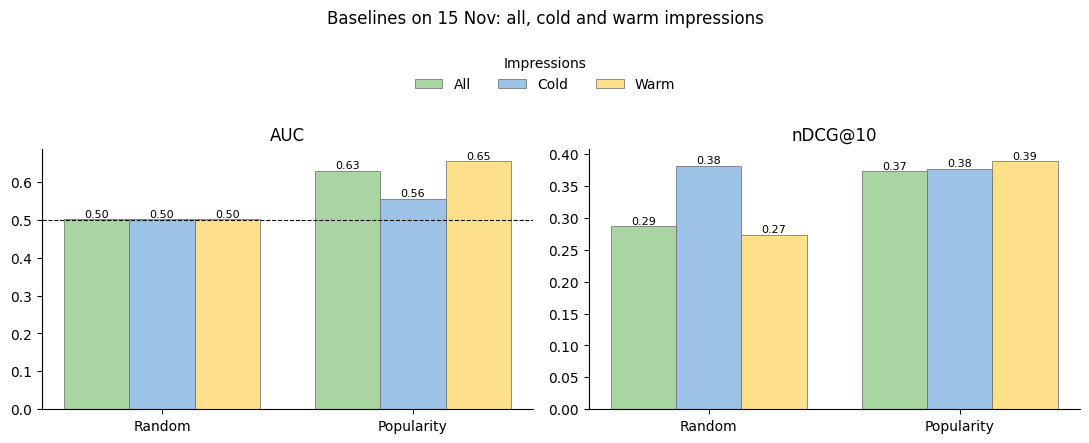

In [17]:
# Chart: AUC and nDCG@10 for each model, all / cold / warm impressions
plot = final.reset_index()
names = list(models.keys())
colors = {"all": "#A8D5A2", "cold": "#9CC3E6", "warm": "#FFE08A"}   # light green / light blue / light yellow
labels = {"all": "All", "cold": "Cold", "warm": "Warm"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), facecolor="white")
width = 0.26
for ax, metric, title in zip(axes, ["auc", "ndcg@10"], ["AUC", "nDCG@10"]):
    ax.set_facecolor("white")
    for i, seg in enumerate(["all", "cold", "warm"]):
        vals = [plot[(plot.model == m) & (plot.segment == seg)][metric].iloc[0] for m in names]
        bars = ax.bar(np.arange(len(names)) + (i - 1) * width, vals, width,
                      label=labels[seg], color=colors[seg], edgecolor="#666666", linewidth=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(np.arange(len(names)))
    ax.set_xticklabels([n.split(" (")[0] for n in names])
    ax.set_title(title)
    if metric == "auc":
        ax.axhline(0.5, color="black", lw=0.8, ls="--")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

# One shared legend above both charts
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title="Impressions", loc="upper center",
           bbox_to_anchor=(0.5, 0.94), ncol=3, frameon=False)
fig.suptitle("Baselines on 15 Nov: all, cold and warm impressions", y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.86])
plt.show()

- **Random** gives AUC ≈ 0.50 in every segment, as expected.
- **Popularity is the strongest baseline overall** (AUC 0.6293, MRR 0.2869, nDCG@10 0.3728 vs random 0.5008, 0.2189, 0.2866). Articles clicked often before tend to be clicked again.
- **Popularity is weak on new articles.** AUC falls from 0.6549 on warm impressions to 0.5550 on cold impressions, and on cold impressions its MRR (0.2985) and nDCG@10 (0.3768) are at random's level (0.2986, 0.3819). Articles never shown before all receive the global CTR, so they tie with each other and cannot be told apart. Cold AUC stays somewhat above 0.5 because the global CTR (4.05%) is higher than the CTR of many established articles (e.g. 2.97% for articles shown 10k–99k times, see 2D), but the top positions still go to established high-CTR articles, so MRR and nDCG gain nothing over random.

## 4A. Fair Exposure and Diversity in the Top 10

Ranking metrics show whether clicked articles are ranked high. For each model, we take the **top 10 articles per impression** (which articles users actually see) and measure:
- **Cold share in top 10:** the percentage of top-10 articles that are cold (new). This is the project's fair-exposure measure.
- **Unique categories:** how many different categories appear in the top 10 (diversity).

Only slates with more than 10 candidates are used (a shorter slate shows every article anyway). As a reference, the average share of cold articles among all candidates in those slates is also printed: a ranking that treats new articles fairly would put roughly that share of cold articles in the top 10.

In [18]:
# 4. What each model puts in the top 10: fair exposure and diversity
from utils.metrics import add_rank, topk, topk_diversity

exposure_rows = {}
cols = ["impression_id", "news_id", "category", "cold_article"]
for name, score_col in models.items():
    ranked = add_rank(evals[cols + [score_col]], score_col)          # rank 1 = highest score
    top10 = topk(ranked, "rank", k=10)                               # top 10 per impression
    exposure_rows[name] = topk_diversity(top10, "category", cold_col="cold_article", k=10)
    del ranked, top10

top10_table = pd.DataFrame(exposure_rows).T
top10_table["cold share in top 10 %"] = 100 * top10_table["cold_share"]

# Reference: share of cold articles among all candidates in the same slates (> 10 candidates)
slate_size = evals.groupby("impression_id")["news_id"].transform("size")
cold_available = 100 * evals[slate_size > 10].groupby("impression_id")["cold_article"].mean().mean()
print(f"Average share of cold articles per slate (slates with > 10 articles): {cold_available:.2f}%")

display(top10_table[["cold share in top 10 %", "unique_categories", "n_lists"]]
        .style.format({"cold share in top 10 %": "{:.2f}", "unique_categories": "{:.2f}", "n_lists": "{:,.0f}"}))

Average share of cold articles per slate (slates with > 10 articles): 20.13%


,cold share in top 10 %,unique_categories,n_lists
Random,20.55,6.50,"294,491"
Popularity (α=10),15.28,6.08,"294,491"


Random ranking (the fair reference, since it ignores history) puts 20.55% cold articles in the top 10, close to the 20.13% available in the slates. Popularity puts fewer new articles in the top 10 (15.28%) and shows slightly fewer categories (6.08 vs 6.50 for random), because it fills the top of the list with the same established, frequently clicked articles.

##4B. Where Do New Articles Appear in the Ranking?

For each position 1–10, the share of articles at that position that are cold. Random ranking keeps about 20% at every position, so it serves as the fair reference.

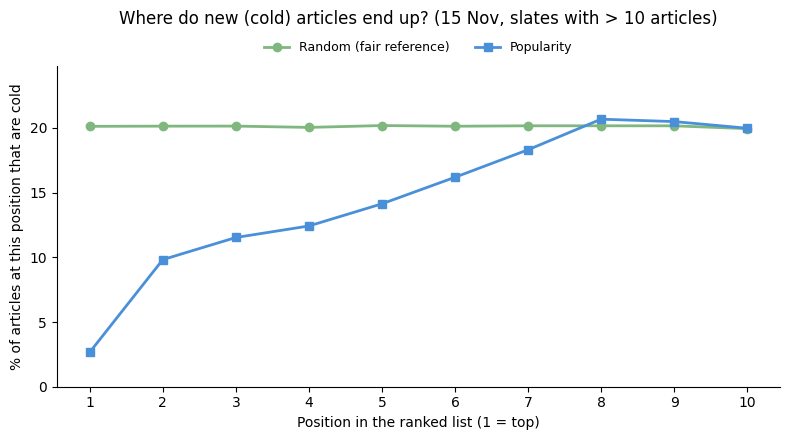

In [19]:
# Where do new articles end up in the ranking?
cols = ["impression_id", "news_id", "cold_article"]
slate_size = evals.groupby("impression_id")["news_id"].transform("size")
big = evals[slate_size > 10]                                   # slates where ranking decides what is shown

line_styles = {"Random": ("#7FB77E", "o"), "Popularity": ("#4A90D9", "s")}
fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="white")
for name, score_col in models.items():
    ranked = add_rank(big[cols + [score_col]], score_col)
    by_pos = ranked[ranked["rank"] <= 10].groupby("rank")["cold_article"].mean() * 100
    short = name.split(" (")[0]
    color, marker = line_styles[short]
    label = short + " (fair reference)" if short == "Random" else short
    ax.plot(by_pos.index, by_pos.values, marker=marker, color=color, label=label, lw=2)
    del ranked

ax.set_xticks(range(1, 11))
ax.set_xlabel("Position in the ranked list (1 = top)")
ax.set_ylabel("% of articles at this position that are cold")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.set_title("Where do new (cold) articles end up? (15 Nov, slates with > 10 articles)", pad=30)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9)  # above the plot
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

Popularity puts a cold article at position 1 only about 3% of the time and reaches the fair ~20% only at positions 8–10, so new articles are pushed to the positions users are least likely to see, even though brand-new articles have the highest CTR on 15 Nov (6.64%, from 2D).

## 5. Save Scores for the Final Comparison (Step 6)
The popularity score for every candidate is saved to `data/scores/` (`impression_id`, `news_id`, `score`; higher = more relevant), taken directly from the scored candidate tables:
- **Test (15 Nov):** `step2_popularity.parquet` (history 9–14 Nov, same scores as the final results)
- **Tune (14 Nov):** `step2_popularity_tune.parquet` (history 9–13 Nov)

Each (`impression_id`, `news_id`) pair appears once, so files from different models can be joined on these two columns.

In [20]:
# 5. Save 15 Nov (Test) and 14 Nov (Tune) popularity scores for later steps
SCORES_DIR = Path(config.SCORES_DIR)
SCORES_DIR.mkdir(parents=True, exist_ok=True)

# Tune-day scores with the chosen α (the tuning loop left the last α tried in this column)
tune["score_pop"] = smoothed_ctr(tune, BEST_POP_ALPHA, global_ctr["tune"])

for day, df, n_rows in [("eval", evals, 14_085_557), ("tune", tune, 17_400_106)]:
    # Checks: every candidate once, no duplicate (impression, article) pairs, no missing scores
    assert len(df) == n_rows, (day, len(df))
    assert not df.duplicated(["impression_id", "news_id"]).any(), day
    out = df[["impression_id", "news_id", "score_pop"]].rename(columns={"score_pop": "score"})
    assert np.isfinite(out["score"]).all(), day
    file = "step2_popularity.parquet" if day == "eval" else "step2_popularity_tune.parquet"
    out.to_parquet(SCORES_DIR / file, index=False)
    print(f"Saved {file}: {len(out):,} rows")

# Check: reading the saved Test file back and joining on (impression_id, news_id)
# gives exactly the final-results score on every row
saved = pd.read_parquet(SCORES_DIR / "step2_popularity.parquet")
check = evals[["impression_id", "news_id", "score_pop"]].merge(saved, on=["impression_id", "news_id"], how="left")
assert np.array_equal(check["score"].to_numpy(), check["score_pop"].to_numpy())
print("✓ Saved Test scores match the final results row by row")
del saved, check
_ = gc.collect()

Saved step2_popularity.parquet: 14,085,557 rows
Saved step2_popularity_tune.parquet: 17,400,106 rows
✓ Saved Test scores match the final results row by row


## 6. Summary
| | Tune (14 Nov) | Test (15 Nov) | Test, cold impressions |
|---|---|---|---|
| Popularity AUC | 0.6076 | 0.6293 | 0.5550 |
| Random AUC | – | 0.5008 | 0.5006 |

- Popularity (α = 10) is the stronger of the two baselines (Test AUC 0.6293, nDCG@10 0.3728).
- It fails on cold-start: on cold impressions its MRR and nDCG@10 are no better than random, and it rarely ranks new articles near the top (15.28% of the top 10 vs a fair ~20%), even though readers click them most.